In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from pathlib import Path

trial_path = Path("data/eye_tracking_data.xlsx")
participant_path = Path("data/participant.xlsx")

trial = pd.read_excel(trial_path)
participant = pd.read_excel(participant_path)

In [2]:
# Combine STAT-A and STAT-B
trial["Dataset"] = trial["Dataset_Abbreviation"].replace({
    "STAT-A": "STAT",
    "STAT-B": "STAT"
})

In [3]:
participant_scored = participant.copy()

participant_scored["MajorGroup"] = (
    participant_scored["subject"].map({
        1: "Geography",
        0: "Non-geography"
    })
)

print(participant_scored["MajorGroup"].value_counts())


MajorGroup
Geography        128
Non-geography     94
Name: count, dtype: int64


In [4]:
metric_families = {
    "AOI allocation": [
        "fix_ratio_kz",
        "fix_ratio_ra"
    ],

    "Fixation timing": [
        "Total_duration_of_whole_fixations",
        "Average_duration_of_whole_fixations",
        "Duration_of_first_whole_fixation",
    ],

    "Saccade behavior": [
        "Number_of_saccades",
        "Average_amplitude_of_saccades",
        "Total_amplitude_of_saccades",
        "Amplitude_of_first_saccade",
    ],
}
metric_families["Behavioral performance"] = [
    "Duration_of_interval"
]

In [5]:
all_eye_metrics = [
    metric
    for metrics in metric_families.values()
    for metric in metrics
]

missing_columns = [
    metric
    for metric in all_eye_metrics
    if metric not in trial.columns
]

print("Metrics not found:", missing_columns)

# Keep only metrics that are present
metric_families = {
    family: [
        metric for metric in metrics
        if metric in trial.columns
    ]
    for family, metrics in metric_families.items()
}

all_eye_metrics = [
    metric
    for metrics in metric_families.values()
    for metric in metrics
]

Metrics not found: []


In [6]:
participant_dataset_mean = (
    trial.groupby(
        ["ParticipantID", "Dataset"],
        observed=True
    )[all_eye_metrics]
    .mean()
    .reset_index()
)

participant_eye_mean = (
    participant_dataset_mean
    .groupby(
        "ParticipantID",
        observed=True
    )[all_eye_metrics]
    .mean()
    .reset_index()
)

In [7]:
analysis_data = participant_eye_mean.merge(
    participant_scored[
        [
            "ParticipantID",
            "MajorGroup",
            "sex",
        ]
    ],
    on="ParticipantID",
    how="inner",
    validate="one_to_one"
)

print("Number of matched participants:", len(analysis_data))
print(analysis_data["MajorGroup"].value_counts())


Number of matched participants: 210
MajorGroup
Geography        119
Non-geography     91
Name: count, dtype: int64


In [8]:
log_transform_metrics = {
    "Duration_of_interval",
    "Total_duration_of_whole_fixations",
    "Duration_of_first_whole_fixation",
    "Number_of_saccades",
    "Total_amplitude_of_saccades",
    "ConvexHullArea"
}

In [9]:
def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    number_of_tests = len(p_values)

    order = np.argsort(p_values)
    adjusted = np.empty(number_of_tests)

    previous = 0

    for rank, index in enumerate(order):
        adjusted_p = (
            number_of_tests - rank
        ) * p_values[index]

        adjusted_p = min(adjusted_p, 1.0)
        adjusted_p = max(adjusted_p, previous)

        adjusted[index] = adjusted_p
        previous = adjusted_p

    return adjusted

In [10]:
def hedges_g(group1, group2):
    """
    Effect direction:
    group1 - group2
    """

    group1 = np.asarray(group1)
    group2 = np.asarray(group2)

    n1 = len(group1)
    n2 = len(group2)

    pooled_sd = np.sqrt(
        (
            (n1 - 1) * np.var(group1, ddof=1) +
            (n2 - 1) * np.var(group2, ddof=1)
        ) /
        (n1 + n2 - 2)
    )

    if pooled_sd == 0:
        return np.nan

    cohens_d = (
        np.mean(group1) -
        np.mean(group2)
    ) / pooled_sd

    correction = (
        1 -
        3 / (
            4 * (n1 + n2) - 9
        )
    )

    return cohens_d * correction

In [11]:
def compare_groups(
    data,
    group_column,
    reference_group,
    comparison_group,
    metric_families,
    log_transform_metrics
):
    results = []

    for family, metrics in metric_families.items():

        for metric in metrics:

            reference_raw = data.loc[
                data[group_column] == reference_group,
                metric
            ].dropna()

            comparison_raw = data.loc[
                data[group_column] == comparison_group,
                metric
            ].dropna()

            # Data used for inferential tests
            if metric in log_transform_metrics:

                reference_test = reference_raw[
                    reference_raw > 0
                ]

                comparison_test = comparison_raw[
                    comparison_raw > 0
                ]

                reference_test = np.log(
                    reference_test
                )

                comparison_test = np.log(
                    comparison_test
                )

                test_scale = "Log-transformed"

            else:
                reference_test = reference_raw
                comparison_test = comparison_raw
                test_scale = "Raw"

            # Welch's t-test
            t_result = stats.ttest_ind(
                comparison_test,
                reference_test,
                equal_var=False,
                nan_policy="omit"
            )

            # Welch–Satterthwaite degrees of freedom
            n1 = len(comparison_test)
            n2 = len(reference_test)

            variance1 = comparison_test.var(ddof=1)
            variance2 = reference_test.var(ddof=1)

            numerator = (
                variance1 / n1 +
                variance2 / n2
            ) ** 2

            denominator = (
                (variance1 / n1) ** 2 /
                (n1 - 1)
                +
                (variance2 / n2) ** 2 /
                (n2 - 1)
            )

            welch_df = numerator / denominator

            # Nonparametric sensitivity analysis
            mann_whitney = stats.mannwhitneyu(
                comparison_raw,
                reference_raw,
                alternative="two-sided"
            )

            results.append({
                "Metric_family": family,
                "Metric": metric,

                "Reference_group":
                    reference_group,

                "Reference_N":
                    len(reference_raw),

                "Reference_Mean":
                    reference_raw.mean(),

                "Reference_SD":
                    reference_raw.std(ddof=1),

                "Comparison_group":
                    comparison_group,

                "Comparison_N":
                    len(comparison_raw),

                "Comparison_Mean":
                    comparison_raw.mean(),

                "Comparison_SD":
                    comparison_raw.std(ddof=1),

                "Mean_Difference":
                    comparison_raw.mean() -
                    reference_raw.mean(),

                "Test_scale":
                    test_scale,

                "Welch_t":
                    t_result.statistic,

                "Welch_df":
                    welch_df,

                "p_value":
                    t_result.pvalue,

                "Hedges_g":
                    hedges_g(
                        comparison_test,
                        reference_test
                    ),

                "Mann_Whitney_U":
                    mann_whitney.statistic,

                "p_Mann_Whitney":
                    mann_whitney.pvalue
            })

    results = pd.DataFrame(results)

    # Apply Holm correction within each metric family
    results["p_Holm_within_family"] = (
        results
        .groupby(
            "Metric_family"
        )["p_value"]
        .transform(holm_adjust)
    )

    results["Significance"] = np.select(
        [
            results["p_Holm_within_family"] < 0.001,
            results["p_Holm_within_family"] < 0.01,
            results["p_Holm_within_family"] < 0.05
        ],
        [
            "***",
            "**",
            "*"
        ],
        default="ns"
    )

    return results

In [12]:
major_results = compare_groups(
    data=analysis_data,
    group_column="MajorGroup",
    reference_group="Non-geography",
    comparison_group="Geography",
    metric_families=metric_families,
    log_transform_metrics=log_transform_metrics
)

major_results[
    [
        "Metric_family",
        "Metric",
        "Reference_N",
        "Reference_Mean",
        "Reference_SD",
        "Comparison_N",
        "Comparison_Mean",
        "Comparison_SD",
        "Mean_Difference",
        "Welch_t",
        "Welch_df",
        "p_value",
        "p_Holm_within_family",
        "Hedges_g",
        "Significance"
    ]
]

,Metric_family,Metric,Reference_N,Reference_Mean,Reference_SD,Comparison_N,Comparison_Mean,Comparison_SD,Mean_Difference,Welch_t,Welch_df,p_value,p_Holm_within_family,Hedges_g,Significance
0,AOI allocation,fix_ratio_kz,91,0.195122,0.026320,119,0.192670,0.024458,-0.002452,-0.689717,186.183466,0.491231,0.491231,-0.096645,ns
1,AOI allocation,fix_ratio_ra,91,0.074496,0.013353,119,0.078946,0.009385,0.004450,2.708343,154.065926,0.007527,0.015054,0.393256,*
2,Fixation timing,Total_duration_of_whole_fixations,91,15230.409745,4517.275676,119,15709.540339,3587.957132,479.130594,1.149869,170.650350,0.251807,0.755421,0.163984,ns
3,Fixation timing,Average_duration_of_whole_fixations,91,251.551917,25.575604,119,251.199929,27.571198,-0.351988,-0.095530,200.356110,0.923989,1.000000,-0.013123,ns
4,Fixation timing,Duration_of_first_whole_fixation,91,177.005380,25.020344,119,175.284196,20.541884,-1.721184,-0.402993,178.238528,0.687436,1.000000,-0.056992,ns
5,Saccade behavior,Number_of_saccades,91,53.394512,14.093076,119,54.950667,11.756884,1.556155,1.148511,166.039474,0.252410,0.504819,0.164612,ns
6,Saccade behavior,Average_amplitude_of_saccades,91,4.006461,0.370571,119,3.859816,0.375880,-0.146646,-2.824121,195.180098,0.005233,0.020932,-0.391111,*
7,Saccade behavior,Total_amplitude_of_saccades,91,203.713997,55.076429,119,203.082091,47.450406,-0.631906,0.193765,175.603399,0.846584,0.846584,0.027483,ns
8,Saccade behavior,Amplitude_of_first_saccade,91,5.146561,0.881962,119,4.879115,0.903237,-0.267446,-2.154887,196.066068,0.032390,0.097170,-0.298046,ns
9,Behavioral performance,Duration_of_interval,91,21271.115463,4494.439835,119,22541.077056,3631.315374,1269.961593,2.480082,162.236116,0.014156,0.014156,0.356927,*


In [13]:
major_significant = major_results[
    major_results[
        "p_Holm_within_family"
    ] < 0.05
].copy()

major_significant

,Metric_family,Metric,Reference_group,Reference_N,Reference_Mean,Reference_SD,Comparison_group,Comparison_N,Comparison_Mean,Comparison_SD,Mean_Difference,Test_scale,Welch_t,Welch_df,p_value,Hedges_g,Mann_Whitney_U,p_Mann_Whitney,p_Holm_within_family,Significance
1,AOI allocation,fix_ratio_ra,Non-geography,91,0.074496,0.013353,Geography,119,0.078946,0.009385,0.004450,Raw,2.708343,154.065926,0.007527,0.393256,6484.0,0.014293,0.015054,*
6,Saccade behavior,Average_amplitude_of_saccades,Non-geography,91,4.006461,0.370571,Geography,119,3.859816,0.375880,-0.146646,Raw,-2.824121,195.180098,0.005233,-0.391111,4384.0,0.018253,0.020932,*
9,Behavioral performance,Duration_of_interval,Non-geography,91,21271.115463,4494.439835,Geography,119,22541.077056,3631.315374,1269.961593,Log-transformed,2.480082,162.236116,0.014156,0.356927,6430.0,0.020015,0.014156,*


In [14]:
output_path = Path("eye_tracking_group_comparisons.xlsx")

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    major_results.to_excel(
        writer, sheet_name="Major comparison", index=False
    )
    major_significant.to_excel(
        writer, sheet_name="Major significant", index=False
    )

# print("Results saved")


# 专业分组绘图

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import rcParams

# ============================================================
# 1. Font, colors, and style
# ============================================================

rcParams["font.family"] = "Calibri"
rcParams["font.sans-serif"] = ["Calibri"]
rcParams["axes.unicode_minus"] = False

sns.set_theme(
    style="whitegrid",
    font="Calibri",
    font_scale=1.1
)

palette = {
    "Non-geography": "#E3A84F",
    "Geography": "#5B8DB8"
}

group_order = [
    "Non-geography",
    "Geography"
]

# ============================================================
# 2. Prepare plotting data for the three significant metrics
# ============================================================

plot_data = analysis_data[
    [
        "ParticipantID",
        "MajorGroup",
        "fix_ratio_ra",
        "Average_amplitude_of_saccades",
        "Duration_of_interval"
    ]
].copy()

# Convert response time from milliseconds to seconds for visualization only
plot_data["Response_time_seconds"] = (
    plot_data["Duration_of_interval"] / 1000
)

plot_data.head()


,ParticipantID,MajorGroup,fix_ratio_ra,Average_amplitude_of_saccades,Duration_of_interval,Response_time_seconds
0,P001,Geography,0.068577,4.472150,28189.270644,28.189271
1,P002,Geography,0.079979,3.639434,28725.289015,28.725289
2,P003,Geography,0.078216,3.846652,26159.987829,26.159988
3,P004,Geography,0.073077,3.601568,20206.148295,20.206148
4,P005,Geography,0.081965,3.640076,19945.932008,19.945932


In [16]:
def significance_symbol(p):
    if pd.isna(p):
        return ""
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"


def add_significance_bracket(
    ax,
    x1,
    x2,
    y,
    height,
    label,
    fontsize=20
):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + height, y + height, y],
        color="black",
        linewidth=1.1,
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + height,
        label,
        ha="center",
        va="bottom",
        fontsize=fontsize,
        fontfamily="Calibri",
        color="black"
    )

In [17]:
# Holm-adjusted p-values for the three significant major-group differences
p_correct_aoi = major_results.loc[
    major_results["Metric"] == "fix_ratio_ra",
    "p_Holm_within_family"
].iloc[0]

p_average_saccade_amplitude = major_results.loc[
    major_results["Metric"] == "Average_amplitude_of_saccades",
    "p_Holm_within_family"
].iloc[0]

p_response_time = major_results.loc[
    major_results["Metric"] == "Duration_of_interval",
    "p_Holm_within_family"
].iloc[0]

print("Correct-answer AOI adjusted p:", p_correct_aoi)
print(
    "Average saccade amplitude adjusted p:",
    p_average_saccade_amplitude
)
print("Response time adjusted p:", p_response_time)


Correct-answer AOI adjusted p: 0.015053662289129844
Average saccade amplitude adjusted p: 0.020932320801626034
Response time adjusted p: 0.014156221617043665


In [18]:
plot_data

,ParticipantID,MajorGroup,fix_ratio_ra,Average_amplitude_of_saccades,Duration_of_interval,Response_time_seconds
0,P001,Geography,0.068577,4.472150,28189.270644,28.189271
1,P002,Geography,0.079979,3.639434,28725.289015,28.725289
2,P003,Geography,0.078216,3.846652,26159.987829,26.159988
3,P004,Geography,0.073077,3.601568,20206.148295,20.206148
4,P005,Geography,0.081965,3.640076,19945.932008,19.945932
...,...,...,...,...,...,...
205,P218,Geography,0.075752,4.192659,23106.726243,23.106726
206,P219,Geography,0.090615,3.841483,23065.360227,23.065360
207,P220,Non-geography,0.093649,4.043070,18809.360606,18.809361
208,P221,Geography,0.081457,4.142693,22578.011742,22.578012


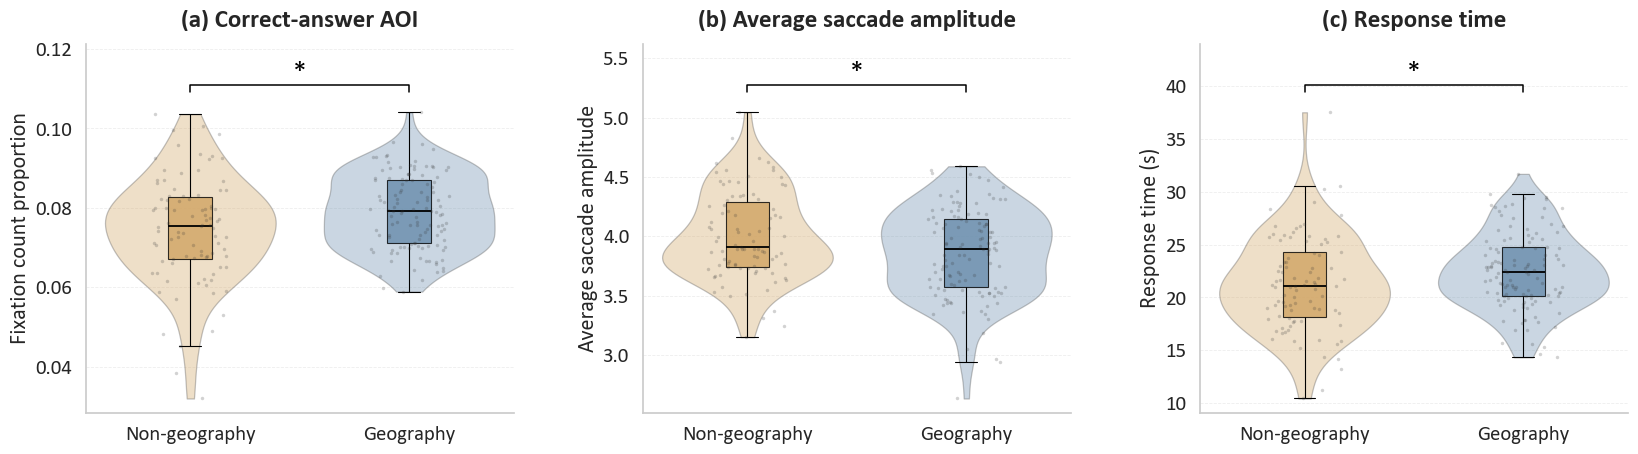

In [19]:
# ============================================================
# 1 x 3 figure: the three significant major-group comparisons
# ============================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(16.5, 5.2)
)


def draw_distribution_panel(ax, metric, title, ylabel, p_value):
    """Draw a violin + box + jittered points panel with a significance bracket."""

    sns.violinplot(
        data=plot_data,
        x="MajorGroup",
        y=metric,
        order=group_order,
        hue="MajorGroup",
        hue_order=group_order,
        palette=palette,
        legend=False,
        inner=None,
        cut=0,
        density_norm="width",
        width=0.78,
        linewidth=0.9,
        alpha=0.35,
        ax=ax
    )

    sns.boxplot(
        data=plot_data,
        x="MajorGroup",
        y=metric,
        order=group_order,
        hue="MajorGroup",
        hue_order=group_order,
        palette=palette,
        legend=False,
        width=0.20,
        showfliers=False,
        boxprops={
            "alpha": 0.80,
            "edgecolor": "black",
            "linewidth": 0.8
        },
        whiskerprops={
            "color": "black",
            "linewidth": 0.8
        },
        capprops={
            "color": "black",
            "linewidth": 0.8
        },
        medianprops={
            "color": "black",
            "linewidth": 1.3
        },
        ax=ax
    )

    sns.stripplot(
        data=plot_data,
        x="MajorGroup",
        y=metric,
        order=group_order,
        color="#333333",
        alpha=0.22,
        size=2.5,
        jitter=0.18,
        ax=ax
    )

    values = plot_data[metric].dropna()
    data_max = values.max()
    data_min = values.min()
    data_range = data_max - data_min

    # Guard against a zero range, although these metrics should vary.
    if data_range == 0 or pd.isna(data_range):
        data_range = max(abs(data_max) * 0.1, 1e-6)

    bracket_y = data_max + data_range * 0.07
    bracket_height = data_range * 0.025

    add_significance_bracket(
        ax=ax,
        x1=0,
        x2=1,
        y=bracket_y,
        height=bracket_height,
        label=significance_symbol(p_value)
    )

    ax.set_ylim(
        max(0, data_min - data_range * 0.05),
        data_max + data_range * 0.24
    )

    ax.set_title(
        title,
        fontsize=18,
        fontweight="bold",
        pad=12
    )
    ax.set_xlabel("")
    ax.set_ylabel(ylabel, fontsize=16)


# (a) Correct-answer AOI fixation proportion
draw_distribution_panel(
    ax=axes[0],
    metric="fix_ratio_ra",
    title="(a) Correct-answer AOI",
    ylabel="Fixation count proportion",
    p_value=p_correct_aoi
)

# (b) Average saccade amplitude
draw_distribution_panel(
    ax=axes[1],
    metric="Average_amplitude_of_saccades",
    title="(b) Average saccade amplitude",
    ylabel="Average saccade amplitude",
    p_value=p_average_saccade_amplitude
)

# (c) Response time (converted to seconds for display)
draw_distribution_panel(
    ax=axes[2],
    metric="Response_time_seconds",
    title="(c) Response time",
    ylabel="Response time (s)",
    p_value=p_response_time
)

# ============================================================
# Shared formatting and export
# ============================================================

for ax in axes:
    ax.tick_params(
        axis="both",
        labelsize=15
    )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.6,
        alpha=0.35
    )

    ax.grid(
        axis="x",
        visible=False
    )

    sns.despine(
        ax=ax,
        top=True,
        right=True
    )

plt.subplots_adjust(
    left=0.055,
    right=0.99,
    top=0.87,
    bottom=0.16,
    wspace=0.30
)

plt.savefig(
    "major_group_eye_movement_comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
